# 01 Data Exploration

In [25]:
# A first look at the raw data, before any decision (decisions: 02_preprocessing.ipynb)
import sys
sys.path.insert(0, "..")  # makes src importable from notebooks/

import nltk
import pandas as pd
import re

from collections import Counter
from nltk.corpus import stopwords
from src.data import TEXT_COLUMNS, load_splits
from src.preprocessing import DATA_DIR, tokenize

pd.set_option("display.max_colwidth", None)
splits = load_splits()
train = splits["train"]
all_texts = {
    col: [t for split in splits.values() for t in split[col]] for col in TEXT_COLUMNS
}
splits

DatasetDict({
    train: Dataset({
        features: ['observation_1', 'observation_2', 'hypothesis_1', 'hypothesis_2', 'label'],
        num_rows: 16801
    })
    validation: Dataset({
        features: ['observation_1', 'observation_2', 'hypothesis_1', 'hypothesis_2', 'label'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['observation_1', 'observation_2', 'hypothesis_1', 'hypothesis_2', 'label'],
        num_rows: 1532
    })
})

## 1. Sentences per text

In [26]:
# Is every observation really one sentence? Count the sentence endings (. ! ?) per
# text over all splits; "..." or "?!" counts as one ending.
def endings(text: str) -> int:
    return len(re.findall(r"[.!?]+", text))


per_column = {col: Counter(map(endings, texts)) for col, texts in all_texts.items()}
pd.DataFrame(per_column).fillna(0).astype(int).sort_index()

,observation_1,observation_2,hypothesis_1,hypothesis_2
0,157,151,0,0
1,19174,19181,19137,19131
2,2,1,180,188
3,0,0,15,13
4,0,0,1,1


In [27]:
observations = all_texts["observation_1"] + all_texts["observation_2"]
hypotheses = all_texts["hypothesis_1"] + all_texts["hypothesis_2"]
print("observations without ending:", [t for t in observations if endings(t) == 0][:5])
print("observations with 2+ endings:", [t for t in observations if endings(t) >= 2])
print("hypotheses with 2+ endings:", [t for t in hypotheses if endings(t) >= 2][:8])

observations without ending: ['Julie was ready to go on her vacation', "Kim couldn't make herself vomit with her finger", 'Tanya wanted to go to the dance with Tim', "Thomas is starting his first job at McDonald's", 'Tim loved going hunting']
observations with 2+ endings: ['Jill had to attend a dancing class around 8 P.M.', 'Jill had to attend a dancing class around 8 P.M.', 'He left immediately.,.']
hypotheses with 2+ endings: ['Irene was sure it would be easy.".', 'Iris catch down Lisa’s phone to the floor.".', 'My neighbor asked me to take care of their dog while they went on vacation. I agreed.', 'Samuel moved the chair next to to the fire place.".', 'Jeremy saw a coach run across his desk.".', "OUCH!  Mary's foot was hurt, but she kept on playing.", 'We concentrated and did not talk the whole time.".', 'Penny decided not to sell work at a gallery. She had three pieces to sell.']


In [28]:
# Observations are practically always one sentence: 0.8% have no final full stop, 3
# have two endings (the abbreviation "P.M." and a typo). About 1% of the hypotheses
# have two or more sentences, so the tokenizer has to split sentences first, otherwise
# the inner full stop stays glued to the word ("vacation." instead of "vacation" ".").

## 2. Characters

In [29]:
# Which characters besides letters, digits and spaces occur at all?
chars = Counter(
    c
    for texts in all_texts.values()
    for t in texts
    for c in t
    if not c.isalnum() and c != " "
)
print(chars.most_common())

[('.', 75535), ("'", 9775), (',', 7050), ('!', 2025), ('-', 794), ('"', 155), ('$', 134), ('’', 34), ('?', 28), (':', 27), ('&', 20), ('/', 13), (';', 12), ('+', 10), ('�', 8), ('%', 8), ('\n', 6), ('{', 4), ('}', 4), ('`', 3), ('\\', 3), ('(', 2), (')', 2), ('´', 1)]


In [30]:
# Examples of rare ones: typographic apostrophe, line break, broken encoding, braces
for ch in ["’", "\n", "�", "{"]:
    print(repr(ch), [t for texts in all_texts.values() for t in texts if ch in t][:3])

'’' ['Iris catch down Lisa’s phone to the floor.".', 'John’s airline decided to take its workers on a company outing.', 'All of Judy’s plants were gone.']
'\n' ['Caroline almost lost her shoes\n.', 'It was packed and the sand was\ncrowded and everyone was unfriendly.', "I decided to pay a visit to someone I've been dating online\nbut couldn't afford it."]
'�' ["Jo��o was frustrated at his country's government.", 'He opened the envelope and was disappointed he hadn���t been accepted.', 'Alex took his clothes to his Mom���s house for her to clean.']
'{' ['{}.', '{}.', '{}.']


In [31]:
# Only the typographic apostrophe (34x) matters for tokenization: "Lisa’s" has to
# become "Lisa's", otherwise the tokenizer splits it into "lisa" "’" "s". Line breaks
# count as spaces. The broken characters (8x) and the "{}." hypotheses (empty entries
# in train) come up again in 02_preprocessing.ipynb (broken entries).

## 3. Lengths

In [32]:
# How long are the texts in tokens? Needed for the truncation decision. Tokens as
# nltk.word_tokenize gives them, punctuation included, so this is an upper bound.
# The RNN reads one story per candidate: O1, h and O2 plus two separators.
lengths = pd.DataFrame(
    {col: [len(nltk.word_tokenize(t)) for t in ts] for col, ts in all_texts.items()}
)
stories = {"story with h1": "hypothesis_1", "story with h2": "hypothesis_2"}
for name, h in stories.items():
    lengths[name] = lengths["observation_1"] + lengths[h] + lengths["observation_2"] + 2
lengths.describe(percentiles=[0.5, 0.9, 0.99]).round(1)

,observation_1,observation_2,hypothesis_1,hypothesis_2,story with h1,story with h2
count,19333.0,19333.0,19333.0,19333.0,19333.0,19333.0
mean,9.2,10.6,9.6,9.6,31.4,31.5
std,2.6,2.9,3.2,3.2,5.5,5.5
min,3.0,3.0,1.0,1.0,14.0,15.0
50%,9.0,11.0,9.0,9.0,31.0,31.0
90%,13.0,14.0,13.0,14.0,38.0,39.0
99%,16.0,17.0,20.0,21.0,45.0,45.7
max,20.0,20.0,35.0,35.0,61.0,63.0


In [33]:
# Longest text per column (in tokens)
lengths.max()

observation_1    20
observation_2    20
hypothesis_1     35
hypothesis_2     35
story with h1    61
story with h2    63
dtype: int64

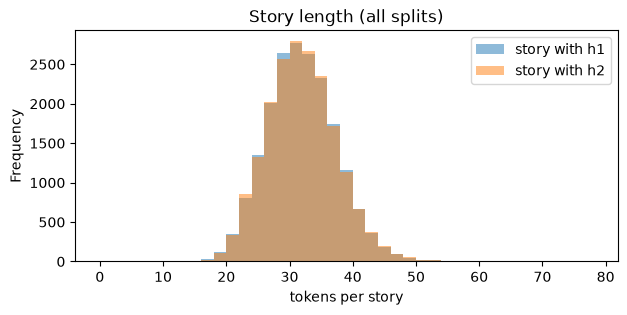

In [34]:
ax = lengths[list(stories)].plot.hist(bins=range(0, 80, 2), alpha=0.5, figsize=(7, 3))
ax.set_xlabel("tokens per story")
ax.set_title("Story length (all splits)");

In [35]:
# Stories are short: 31 tokens on average, 99% have at most 46, the longest 63 (with
# h2, punctuation included). The longest ones have a hypothesis with two or three
# sentences.

## 4. Sentence endings

In [36]:
# Which character does each text end with? Input for the punctuation decision.
def last_char(text: str) -> str:
    c = text.strip()[-1:]
    return c if not c.isalnum() else "letter/digit"


per_column = {col: Counter(map(last_char, texts)) for col, texts in all_texts.items()}
pd.DataFrame(per_column).fillna(0).astype(int)

,observation_1,observation_2,hypothesis_1,hypothesis_2
.,19107,17309,19333,19333
!,63,1855,0,0
letter/digit,155,145,0,0
?,5,11,0,0
",",3,6,0,0
"""",0,4,0,0
\,0,1,0,0
/,0,2,0,0


In [37]:
# Observations that do not end with a full stop, by last character
for ending in ["!", "?", '"', "letter/digit", ",", "/", "\\"]:
    examples = [t for t in observations if last_char(t) == ending]
    print(f"{ending!r}: {len(examples)}", examples[:4])

'!': 1918 ['Jenny woke up excited for her big picnic today!', 'My two kids love to play dress up!', "Today was Iris's fifth birthday!", 'Anna wanted fish in her new tank!']
'?': 16 ['The other day I wondered where does honey come from?', 'Anthony receives a lot of spam, and he wondered who else did?', 'Is it possible animals understand movies?', 'Sam moved her car towards the pick-up window?']
'"': 4 ['The coach replied "Was it raining on both sides of the court?"', 'It said "The first person to find this wagon can keep it."', 'He said "As long as it would take to reach the end of the tunnels."', 'I told him he had the "persimmon pucker."']
'letter/digit': 300 ['Julie was ready to go on her vacation', "Kim couldn't make herself vomit with her finger", 'Tanya wanted to go to the dance with Tim', "Thomas is starting his first job at McDonald's"]
',': 9 ['Heather wanted to challenge her friends to a mud run,', 'I got passed on a promotion at work,', 'Stan decided to purchase a pizza for t

In [38]:
# Every hypothesis ends with ".", in all splits, even with a "!" or "?" inside ("OUCH!
# Mary's foot was hurt, but she kept on playing."), so the final full stop of a
# hypothesis tells nothing. "!" at the end is almost only in observation_2 (about 10%),
# the end of the story. Observations are the same for both candidates of an example,
# so their punctuation cannot tell h1 and h2 apart.

## 5. Stopwords

In [39]:
# What would stopword removal take away? NLTK's English list, the one the course
# notebooks use for topic modeling.
nltk.download("stopwords", quiet=True)
stop = set(stopwords.words("english"))
train_tokens = [t for col in TEXT_COLUMNS for x in train[col] for t in tokenize(x)]
share = 100 * sum(t in stop for t in train_tokens) / len(train_tokens)
print(f"{len(stop)} stopwords, {share:.1f}% of all training tokens")
print(sorted(stop))

198 stopwords, 43.3% of all training tokens
['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an', 'and', 'any', 'are', 'aren', "aren't", 'as', 'at', 'be', 'because', 'been', 'before', 'being', 'below', 'between', 'both', 'but', 'by', 'can', 'couldn', "couldn't", 'd', 'did', 'didn', "didn't", 'do', 'does', 'doesn', "doesn't", 'doing', 'don', "don't", 'down', 'during', 'each', 'few', 'for', 'from', 'further', 'had', 'hadn', "hadn't", 'has', 'hasn', "hasn't", 'have', 'haven', "haven't", 'having', 'he', "he'd", "he'll", "he's", 'her', 'here', 'hers', 'herself', 'him', 'himself', 'his', 'how', 'i', "i'd", "i'll", "i'm", "i've", 'if', 'in', 'into', 'is', 'isn', "isn't", 'it', "it'd", "it'll", "it's", 'its', 'itself', 'just', 'll', 'm', 'ma', 'me', 'mightn', "mightn't", 'more', 'most', 'mustn', "mustn't", 'my', 'myself', 'needn', "needn't", 'no', 'nor', 'not', 'now', 'o', 'of', 'off', 'on', 'once', 'only', 'or', 'other', 'our', 'ours', 'ourselves', 'out', 'over', 'own

In [40]:
# Hypothesis pairs that differ only in stopwords: without stopwords h1 and h2 would
# contain the same words, and the model could not tell them apart any more.
only_stop = []
for h1, h2 in zip(train["hypothesis_1"], train["hypothesis_2"]):
    diff = set(tokenize(h1)) ^ set(tokenize(h2))
    if diff and all(w in stop for w in diff):
        only_stop.append((h1, h2, sorted(diff)))
print(f"{len(only_stop)} pairs ({100 * len(only_stop) / len(train):.1f}%)")
words = Counter(w for _, _, diff in only_stop for w in diff)
print("stopwords that make the difference:", words.most_common(15))
for example in only_stop[:6]:
    print("   ", example)

367 pairs (2.2%)
stopwords that make the difference: [('not', 117), ('up', 39), ('down', 35), ('i', 29), ('no', 29), ('me', 25), ('he', 24), ('the', 24), ('her', 22), ('was', 20), ('after', 20), ('she', 19), ('his', 19), ('before', 18), ('him', 17)]
    ('Amanda is not easily amused.', 'Amanda is easily amused.', ['not'])
    ('She practiced for months to make a basket because she was bad at it.', 'He practiced for months to make a basket because he was bad at it.', ['he', 'she'])
    ('Dale was not caught by the police for speeding.', 'Dale caught of with the police for speeding.', ['by', 'not', 'of', 'was', 'with'])
    ('Del and Simon were playing a game together and Simon won.', 'Del and Simon were playing a game together.', ['won'])
    ('Eric was told not to close his eyes.', 'Eric was told to close his eyes.', ['not'])
    ('Eva and her friends saved down for a raft.', 'Eva and her friends saved up for a raft.', ['down', 'up'])


## 6. Unknown and rare words

In [41]:
# Which tokens have no GloVe vector? Tokens as tokenize() makes them, all splits.
glove_words = set()
with open(DATA_DIR / "glove.6B.300d.txt", encoding="utf-8") as f:
    for line in f:
        glove_words.add(line.split(" ", 1)[0])

counts = {
    name: Counter(t for col in TEXT_COLUMNS for x in split[col] for t in tokenize(x))
    for name, split in splits.items()
}
total = sum(counts.values(), Counter())
unknown = [w for w in total if w not in glove_words]
n_unknown = sum(total[w] for w in unknown)
n_tokens = sum(total.values())
print(f"{len(total):,} different tokens, {len(unknown):,} of them without GloVe vector")
print(f"{n_unknown:,} of {n_tokens:,} tokens ({100 * n_unknown / n_tokens:.2f}%)")

17,290 different tokens, 843 of them without GloVe vector
1,137 of 680,287 tokens (0.17%)


In [42]:
# The 10 most frequent unknown tokens
unknown_table = pd.DataFrame({"token": unknown, "total": [total[w] for w in unknown]})
unknown_table = unknown_table.sort_values(["total", "token"], ascending=[False, True])
unknown_table.reset_index(drop=True).head(10)

,token,total
0,mturk,22
1,selfie,11
2,zaiden,7
3,a+,6
4,selfies,6
5,antonela,5
6,dogwhistle,5
7,fariah,5
8,becouse,4
9,benisha,4


In [ ]:
# Split unknown words with a hyphen into their parts ("air-conditioner" -> "air"
# "conditioner"). Hyphenated words GloVe knows ("well-known") stay as they are.
def split_hyphens(tokens: list[str]) -> list[str]:
    result = []
    for t in tokens:
        if "-" in t and t not in glove_words:
            result += [part for part in t.split("-") if part]
        else:
            result.append(t)
    return result


def summary(counter: Counter, unknown_words: list[str]) -> dict:
    n = sum(counter[w] for w in unknown_words)
    return {
        "different unknown words": len(unknown_words),
        "unknown occurrences": n,
        "unknown % of all tokens": round(100 * n / sum(counter.values()), 3),
    }


total_split = Counter(
    t
    for texts in all_texts.values()
    for text in texts
    for t in split_hyphens(tokenize(text))
)
unknown_split = [w for w in total_split if w not in glove_words]
pd.DataFrame(
    [summary(total, unknown), summary(total_split, unknown_split)],
    index=["as tokenized", "hyphen words split"],
)

,different unknown words,unknown occurrences,unknown % of all tokens
as tokenized,843,1137,0.167
hyphen words split,588,851,0.125


In [44]:
# What the split makes of some unknown hyphen words, and which parts stay unknown
for w in [w for w in unknown if "-" in w][:12]:
    parts = split_hyphens([w])
    print(f"{w:>22} -> {parts}", [p for p in parts if p not in glove_words] or "")

              wolf-dog -> ['wolf', 'dog'] 
            neat-freak -> ['neat', 'freak'] 
         berry-picking -> ['berry', 'picking'] 
            full-swing -> ['full', 'swing'] 
            pre-dental -> ['pre', 'dental'] 
                bb-gun -> ['bb', 'gun'] 
         new-boyfriend -> ['new', 'boyfriend'] 
          scratch-offs -> ['scratch', 'offs'] 
           yellow-gold -> ['yellow', 'gold'] 
          30-years-old -> ['30', 'years', 'old'] 
           spell-bound -> ['spell', 'bound'] 
             low-rider -> ['low', 'rider'] 


In [45]:
# Rare words: tokens with a GloVe vector that occur only a few times in train
known = {w: n for w, n in counts["train"].items() if w in glove_words}
buckets = pd.Series(
    {
        "1x": sum(n == 1 for n in known.values()),
        "2x": sum(n == 2 for n in known.values()),
        "3-5x": sum(3 <= n <= 5 for n in known.values()),
        "6-10x": sum(6 <= n <= 10 for n in known.values()),
        ">10x": sum(n > 10 for n in known.values()),
    },
    name="different words",
)
print(buckets.to_string())
print("words that occur once:", [w for w, n in known.items() if n == 1][:25])

1x       4579
2x       2303
3-5x     3031
6-10x    1756
>10x     3788
words that occur once: ['nicaragua', 'cloudless', 'reprimanding', 'spaceships', 'adriana', 'continent', 'weddings', 'cannon', 'becs', 'enlist', 'bry', 'wheat', 'compton', 'intended', 'perhaps', 'crates', 'torso', 'newbie', 'jewel', 'fay', 'wintry', 'milking', 'll', 'refrigerated', 'nonfiction']


## 7. Hypothesis length and label

In [46]:
# Is the length of a hypothesis a hint for the label? Input for "mean or sum of the
# word vectors": a sum grows with the length, a mean does not.
right, wrong = [], []
for h1, h2, label in zip(train["hypothesis_1"], train["hypothesis_2"], train["label"]):
    l1, l2 = len(tokenize(h1)), len(tokenize(h2))
    right.append(l1 if label == 1 else l2)
    wrong.append(l2 if label == 1 else l1)

different = [(r, w) for r, w in zip(right, wrong) if r != w]
shorter = 100 * sum(r < w for r, w in different) / len(different)
print(f"mean length right: {sum(right) / len(right):.2f}")
print(f"mean length wrong: {sum(wrong) / len(wrong):.2f}")
print(f"{len(different)} pairs with different length, shorter right: {shorter:.1f}%")

mean length right: 8.56
mean length wrong: 8.65
9267 pairs with different length, shorter right: 56.8%


In [47]:
# On average both are equally long, but when they differ, the shorter one is right in
# 57% of the training pairs. That comes from how the hypotheses were written, not from
# the stories. A sum of the word vectors would show the model the length, a mean only
# the content.